# 01 – Exploratory Data Analysis (Task 1)

**Goal of the project:** predict whether a telecom customer will *churn* (cancel their service).
This is **binary classification**: the answer is a class (Yes/No), not a number.

**Goal of this notebook:** look at the data *before* modelling. EDA answers four questions:
1. Is the data clean? (missing values, wrong types, duplicates, outliers)
2. What does the target look like? (is it balanced?)
3. Which features seem related to churn? (these become our expectations for the models)
4. What preprocessing will the models need?

Every chart is followed by an **Insight** cell – the coursework marks insights, not just charts.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, "..")                 # so we can import our own src/ package
from src.data_prep import load_raw, clean, INTERNET_ADDONS

DATA_PATH = "../data/Telco-Customer-Churn.csv"
FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 30)

def save(name):
    """Save the current figure for the report, then show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load and inspect the raw data

In [2]:
raw = load_raw(DATA_PATH)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**What to notice:** 7,043 customers (rows) and 21 columns. `SeniorCitizen`, `tenure` and `MonthlyCharges`
are numeric, but **`TotalCharges` is stored as text** even though it is money. That is a red flag:
something inside the column is not a number.

In [4]:
print("Missing values per column (as pandas sees them):", raw.isna().sum().sum())
print("Fully duplicated rows:", raw.duplicated().sum())
print("Duplicated rows if we ignore customerID:", raw.drop(columns="customerID").duplicated().sum())

# Find the hidden problem in TotalCharges
as_number = pd.to_numeric(raw["TotalCharges"].astype(str).str.strip(), errors="coerce")
blank = raw[as_number.isna()]
print("\nTotalCharges values that are not numbers:", len(blank))
blank[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Missing values per column (as pandas sees them): 0
Fully duplicated rows: 0
Duplicated rows if we ignore customerID: 22

TotalCharges values that are not numbers: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Insight – data quality**
- pandas reports *no* missing values, but 11 `TotalCharges` entries are a blank space `" "`. Missing data is not always `NaN`!
- All 11 have **tenure = 0**: they joined this month and have not been billed yet. So their true total is **0** – filling with the
  mean (≈ 2,280) would be wrong. (`pd.to_numeric(..., errors="coerce")` turns the blanks into NaN, then we fill with 0.)
- There are no duplicate rows. 22 rows repeat once `customerID` is removed, but they are different customers who happen to have
  identical plans (mostly new, single-service customers), so they are genuine and are kept.

## 2. Clean the data

The cleaning rules live in `src/data_prep.py` so that the modelling notebook uses *exactly* the same rules:

| Step | Why |
|---|---|
| `TotalCharges` → number, blanks → 0 | blanks are tenure-0 customers |
| drop `customerID` | an ID has no predictive value; data minimisation |
| "No internet service"/"No phone service" → "No" | `InternetService`/`PhoneService` already hold that fact; avoids duplicated columns |
| `SeniorCitizen` 0/1 → "No"/"Yes" | consistent with every other yes/no column |
| new feature `NumServices` | count of services a customer pays for (feature engineering) |
| `Churn` Yes/No → 1/0 | models need a numeric target; 1 = churned = the *positive* class |

These are fixed rules (nothing is *learned* from the data), so applying them before the train/test split causes no data leakage.

In [5]:
df = clean(raw)
print(df.shape)
print("Missing values after cleaning:", df.isna().sum().sum())
print("TotalCharges dtype:", df["TotalCharges"].dtype)
df.head()

(7043, 21)
Missing values after cleaning: 0
TotalCharges dtype: float64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,NumServices
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,2
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,4
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,4
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,4
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,2


In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80
Churn,7043.0,0.27,0.44,0.00,0.00,0.00,1.00,1.00
NumServices,7043.0,4.15,2.31,1.00,2.00,4.00,6.00,9.00


**Reading `describe()`:** tenure ranges 0–72 months, monthly charges 18–119. The numeric columns are on **very different scales**
(TotalCharges goes up to ~8,700). KNN measures distances, so without scaling TotalCharges would dominate every distance –
we will need a `StandardScaler` for KNN and Logistic Regression (Random Forest does not need it).

## 3. The target: how many customers churn?

Churn
Stayed (0)     5174
Churned (1)    1869
Name: count, dtype: int64
Churn rate: 26.5%


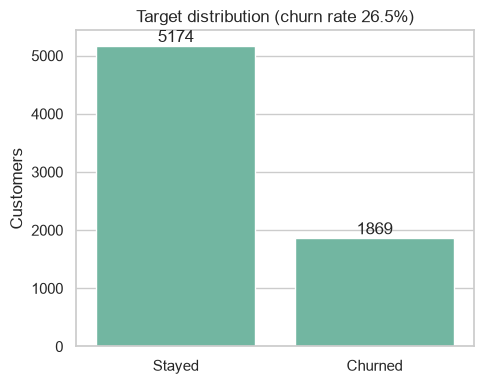

In [7]:
counts = df["Churn"].value_counts().sort_index()
rate = df["Churn"].mean()
print(counts.rename({0: "Stayed (0)", 1: "Churned (1)"}))
print(f"Churn rate: {rate:.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=df["Churn"].map({0: "Stayed", 1: "Churned"}), ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set(title=f"Target distribution (churn rate {rate:.1%})", xlabel="", ylabel="Customers")
save("01_target_distribution")

**Insight – class imbalance:** only **26.5%** of customers churn (1,869 of 7,043). A useless model that always says
"stays" would already be **73.5% accurate**. So accuracy is a misleading score here. We will:
- use a **stratified** train/test split (keeps 26.5% churners in both parts),
- judge models mainly by **F1, recall and ROC-AUC** of the churn class,
- try imbalance fixes (`class_weight="balanced"`, SMOTE).

## 4. Numeric features vs churn

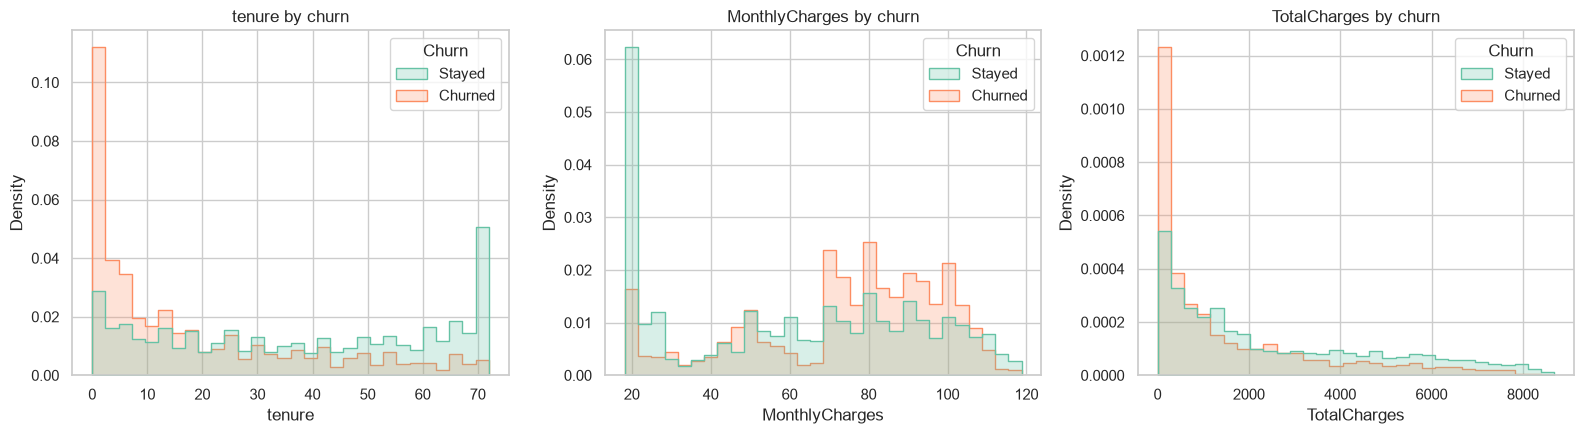

Median values by group:


,tenure,MonthlyCharges,TotalCharges
Churn,,,
Churned,10.0,79.650,703.550
Stayed,38.0,64.425,1679.525


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue=df["Churn"].map({0: "Stayed", 1: "Churned"}),
                 bins=30, stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(f"{col} by churn")
save("02_numeric_distributions")

print("Median values by group:")
df.groupby(df["Churn"].map({0: "Stayed", 1: "Churned"}))[["tenure", "MonthlyCharges", "TotalCharges"]].median()

**Insight – numeric features**
- **Tenure** is the clearest signal: churners have a median tenure of **10 months** vs **38** for loyal customers. Most churn happens early.
- **MonthlyCharges:** churners pay more (median ≈ **79.7** vs **64.4**). The churned group peaks at 70–105, i.e. expensive plans.
- **TotalCharges** is lower for churners simply because they leave early (TotalCharges ≈ tenure × MonthlyCharges).

tenure
0-12     0.474
13-24    0.287
25-48    0.204
49-72    0.095
Name: Churn, dtype: float64


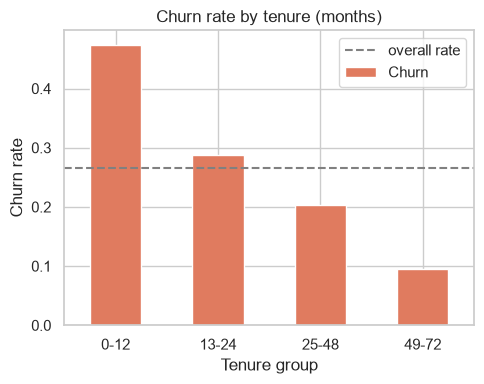

In [9]:
bins = [-1, 12, 24, 48, 72]
labels = ["0-12", "13-24", "25-48", "49-72"]
tenure_group = pd.cut(df["tenure"], bins=bins, labels=labels)
by_group = df.groupby(tenure_group, observed=True)["Churn"].mean()
print(by_group.round(3))

ax = by_group.plot(kind="bar", color="#e07b5f", figsize=(5, 4), rot=0)
ax.set(title="Churn rate by tenure (months)", ylabel="Churn rate", xlabel="Tenure group")
ax.axhline(rate, ls="--", c="grey", label="overall rate"); ax.legend()
save("03_churn_by_tenure_group")

**Insight:** churn falls steadily with tenure – **47%** in the first year, **9.5%** after four years.
The first 12 months are the danger zone where retention offers would matter most.

## 5. Categorical features vs churn

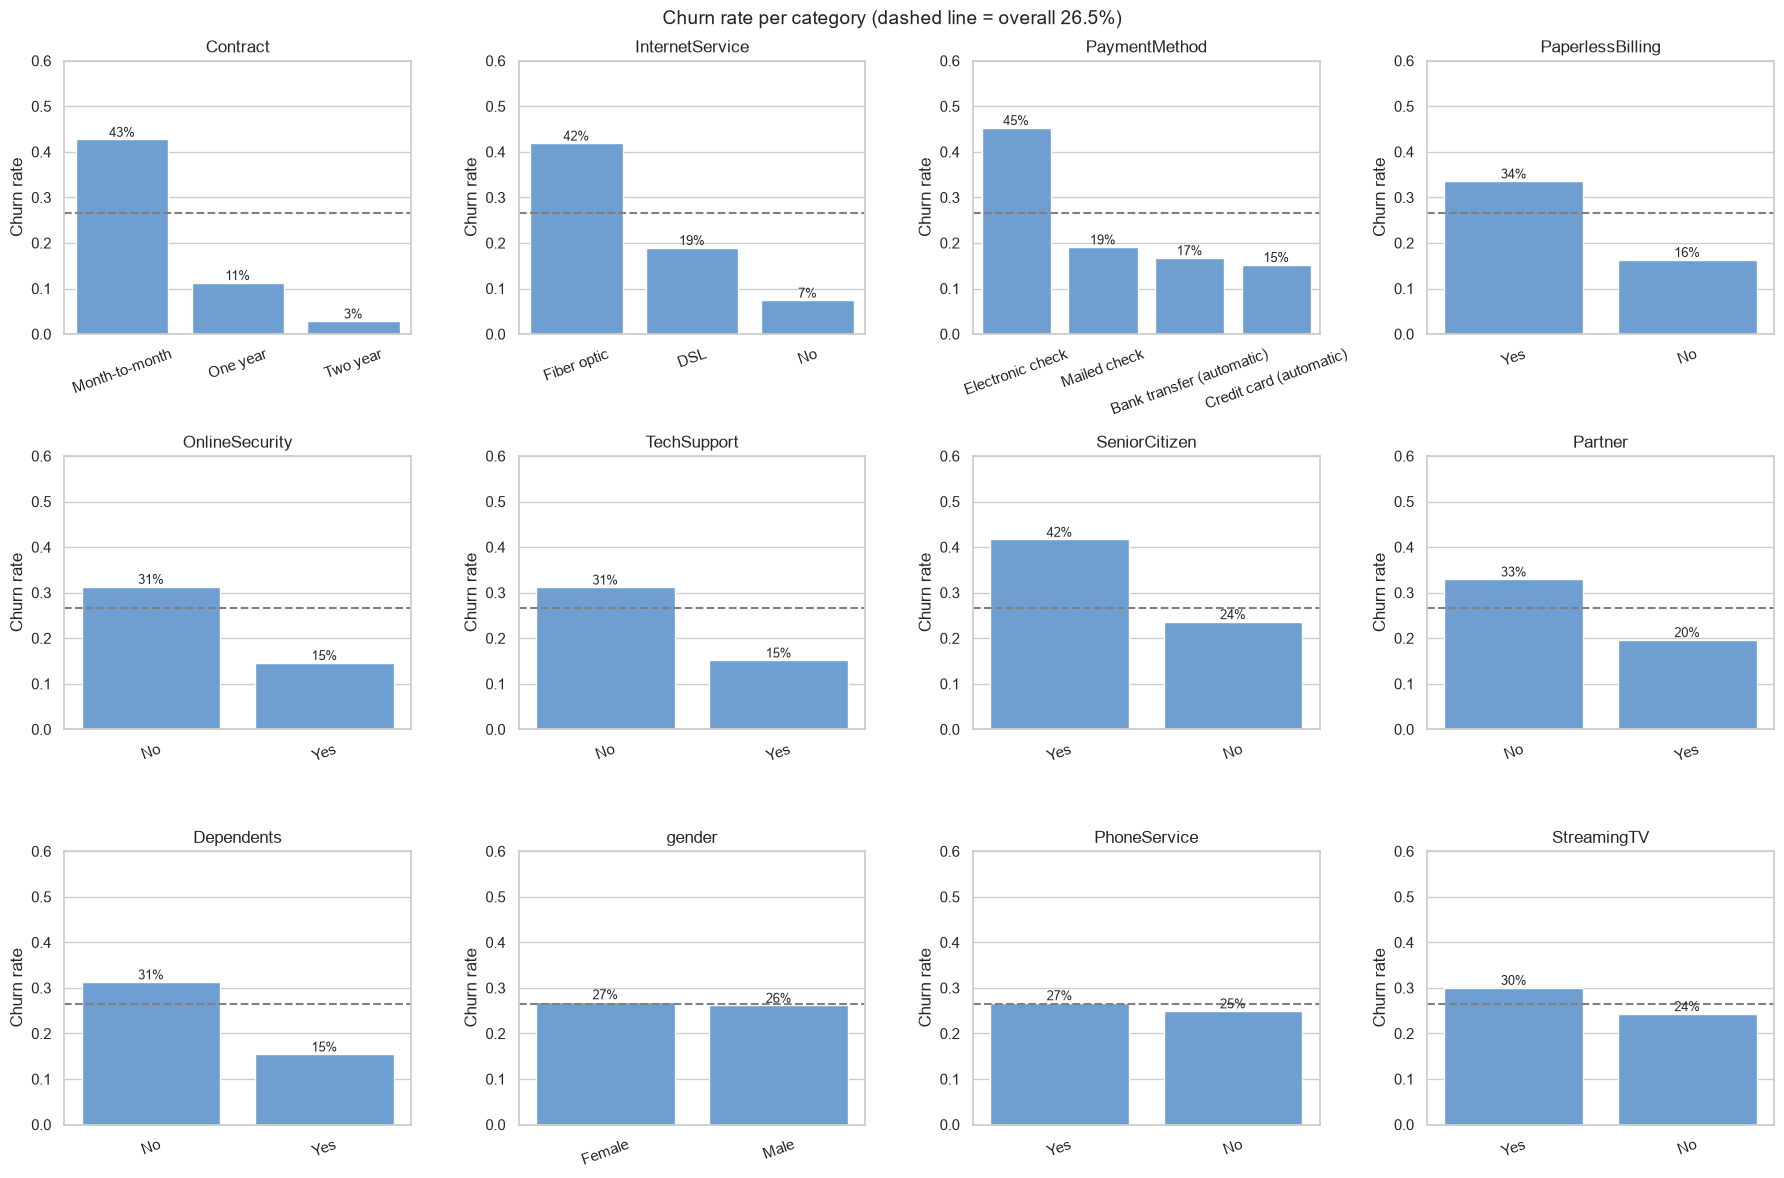

In [10]:
cat_features = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling",
                "OnlineSecurity", "TechSupport", "SeniorCitizen", "Partner",
                "Dependents", "gender", "PhoneService", "StreamingTV"]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for ax, col in zip(axes.ravel(), cat_features):
    churn_rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=churn_rate.index, y=churn_rate.values, ax=ax, color="#5f9ee0")
    ax.axhline(rate, ls="--", c="grey")
    ax.set(title=col, ylabel="Churn rate", xlabel="", ylim=(0, 0.6))
    ax.tick_params(axis="x", rotation=20)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0%}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
fig.suptitle("Churn rate per category (dashed line = overall 26.5%)", fontsize=14)
save("04_churn_by_category")

**Insight – categorical features (strongest first)**
- **Contract:** month-to-month customers churn at **43%**, one-year **11%**, two-year only **3%** – about 15× lower. Contract type is the strongest single predictor.
- **InternetService:** fibre-optic customers churn at **42%** vs 19% for DSL and 7% with no internet – fibre is expensive, so price/value may be the issue.
- **PaymentMethod:** electronic check **45%**, the automatic methods ≈ 15–17%. Automatic payment is a sign of commitment.
- **OnlineSecurity / TechSupport:** customers *without* these add-ons churn at ≈ 42% vs ≈ 15% with them – support services keep people.
- **SeniorCitizen:** seniors churn at **42%** vs 24%. **Partner/Dependents:** single customers without dependants churn more.
- **gender** (27% vs 26%) and **PhoneService** make almost no difference → weak predictors. Gender is also a protected characteristic, which matters for the ethics section.

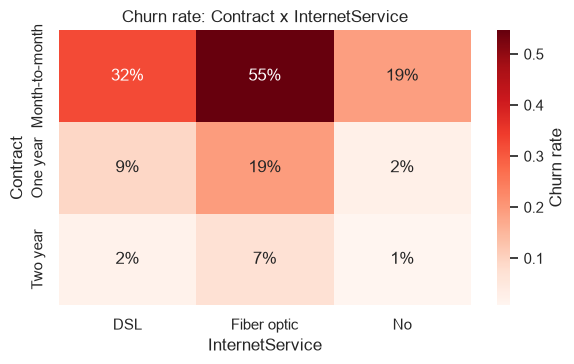

In [11]:
pivot = pd.crosstab(df["Contract"], df["InternetService"], values=df["Churn"], aggfunc="mean")
plt.figure(figsize=(6, 3.8))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", cbar_kws={"label": "Churn rate"})
plt.title("Churn rate: Contract x InternetService")
save("05_contract_internet_heatmap")

**Insight – features interact:** month-to-month + fibre optic customers churn at **55%**, while two-year customers
churn at ≤ 7% whatever their internet type. A model that can combine features (like a Random Forest)
should be able to use such interactions; a linear model only adds effects together.

              mean  count
NumServices              
1            0.109   1264
2            0.310    859
3            0.449    846
4            0.365    965
5            0.313    922
6            0.256    908
7            0.225    676
8            0.124    395
9            0.053    208


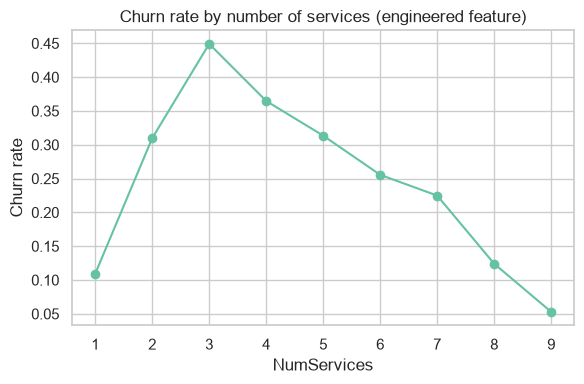

In [12]:
by_services = df.groupby("NumServices")["Churn"].agg(["mean", "count"])
print(by_services.round(3))
ax = by_services["mean"].plot(marker="o", figsize=(6, 4))
ax.set(title="Churn rate by number of services (engineered feature)", xlabel="NumServices", ylabel="Churn rate")
save("06_churn_by_num_services")

**Insight – engineered feature:** the relationship is **not a straight line**. Churn is low for 1 service (**11%**, mostly cheap phone-only plans),
peaks at **3 services (45%)**, then falls steadily to **5%** for customers with all 9. Customers who use many services are "locked in".
A curved pattern like this favours flexible models (KNN, Random Forest) over a purely linear one.

## 6. Correlation between numeric features

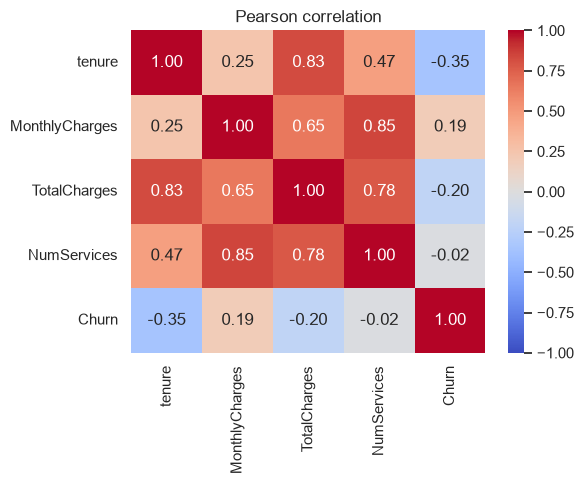

In [13]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "NumServices", "Churn"]]
plt.figure(figsize=(6, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson correlation")
save("07_correlation_heatmap")

**Insight – correlation and multicollinearity**
- `TotalCharges` is strongly correlated with `tenure` (**0.83**) and `MonthlyCharges` (0.65) – it is roughly their product.
  Highly correlated predictors (*multicollinearity*) make Logistic Regression coefficients harder to interpret, but they do not hurt
  prediction much; we keep it and note this when reading coefficients.
- With churn: tenure **−0.35** (longer = less churn), MonthlyCharges **+0.19** (more expensive = more churn).

## 7. Outliers

tenure: 0 outliers by the 1.5*IQR rule
MonthlyCharges: 0 outliers by the 1.5*IQR rule


TotalCharges: 0 outliers by the 1.5*IQR rule


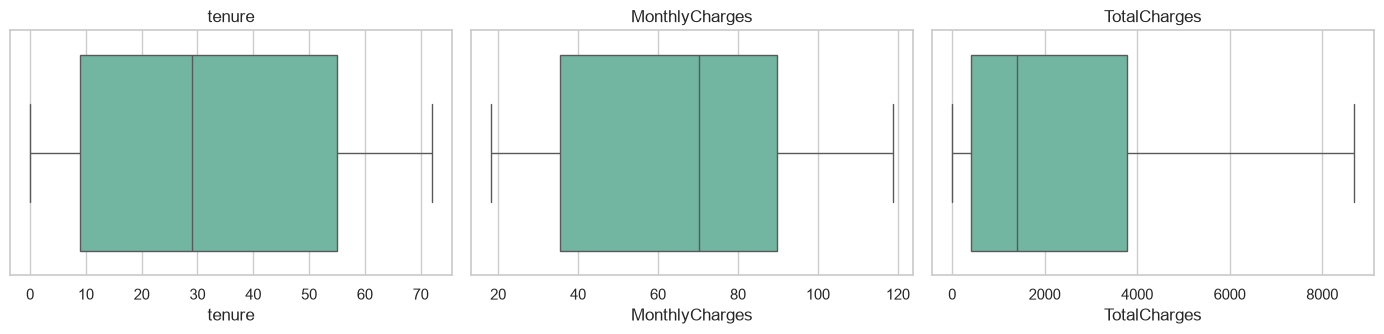

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(x=df[col], ax=ax); ax.set_title(col)
    q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_out} outliers by the 1.5*IQR rule")
save("08_outlier_boxplots")

**Insight:** no values fall outside 1.5 × IQR. All values are in valid ranges (tenure 0–72, charges positive),
so nothing is removed. TotalCharges is right-skewed (many new customers with small totals) – that is real, not an error.

## 8. Extra (syllabus link): PCA and K-means view of the customers

The coursework only requires supervised models, but two unsupervised tools from the module help us *see* the data:
- **PCA** (Week 2) squeezes the ~30 encoded features into 2 new axes that keep the most variance, so we can plot customers.
- **K-means** (Week 9) groups customers into segments *without* looking at the churn label; afterwards we check churn per segment.

Both use distances/variances, so we one-hot encode and **standardise** first.

Encoded features: 24
Variance kept by PC1+PC2: 39.2%
Components needed for 90% variance: 15


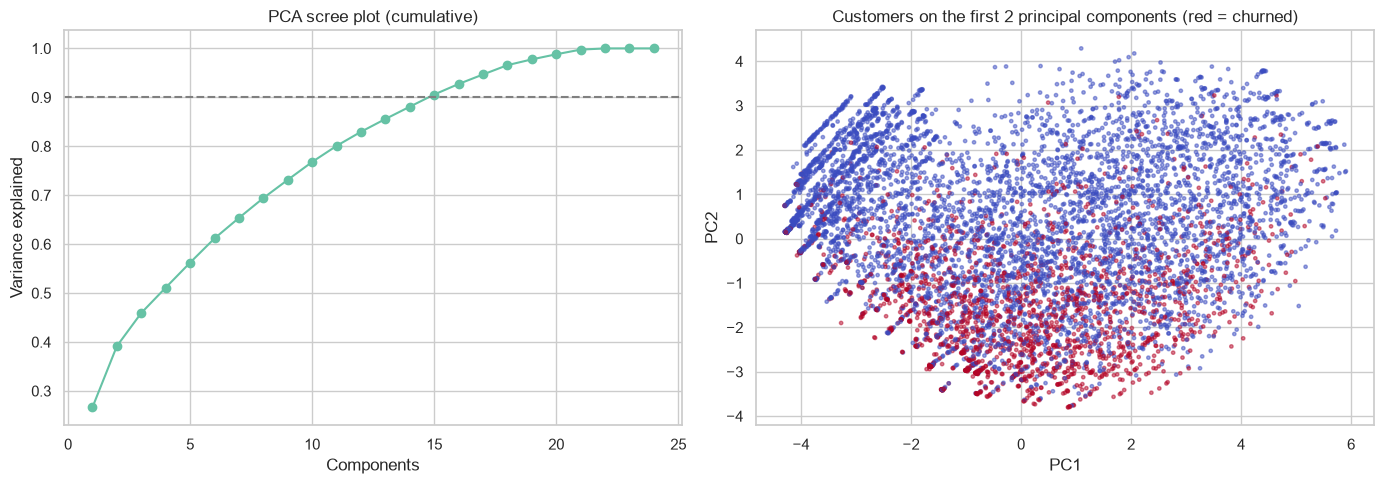

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

X_all = pd.get_dummies(df.drop(columns="Churn"), drop_first=True, dtype=float)
X_scaled = StandardScaler().fit_transform(X_all)

pca = PCA().fit(X_scaled)
cum = np.cumsum(pca.explained_variance_ratio_)
print("Encoded features:", X_all.shape[1])
print(f"Variance kept by PC1+PC2: {cum[1]:.1%}")
print("Components needed for 90% variance:", int(np.argmax(cum >= 0.90) + 1))

Z = pca.transform(X_scaled)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(cum) + 1), cum, marker="o")
axes[0].axhline(0.9, ls="--", c="grey"); axes[0].set(title="PCA scree plot (cumulative)", xlabel="Components", ylabel="Variance explained")
axes[1].scatter(Z[:, 0], Z[:, 1], c=df["Churn"], cmap="coolwarm", s=6, alpha=0.5)
axes[1].set(title="Customers on the first 2 principal components (red = churned)", xlabel="PC1", ylabel="PC2")
save("09_pca")

         customers  churn_rate  tenure  monthly  services
Segment                                                  
0             2352        0.15    59.0    93.40       7.0
1             1629        0.08    24.0    20.20       1.0
2             3062        0.45    12.0    70.93       4.0


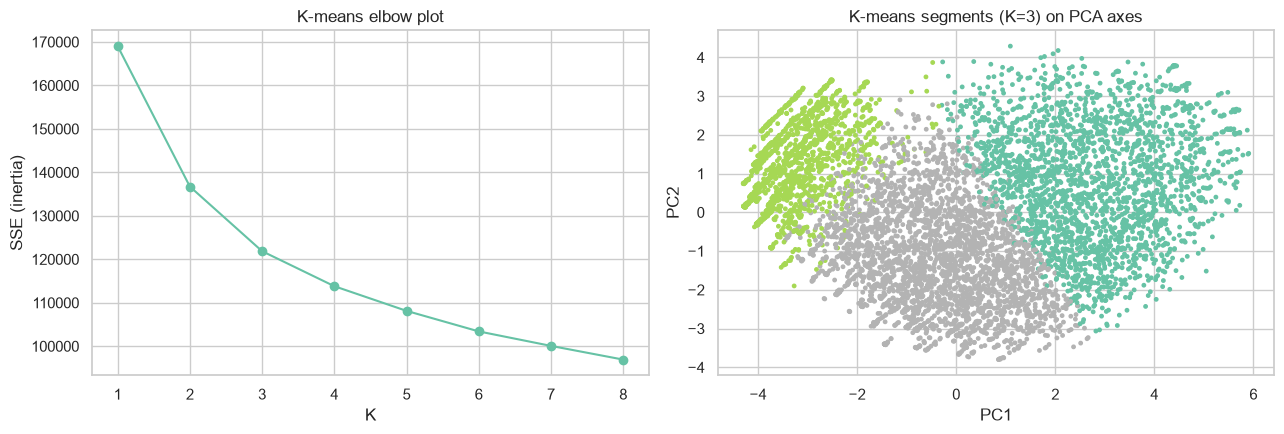

In [16]:
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled).inertia_ for k in range(1, 9)]
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_scaled)
seg = df.assign(Segment=km.labels_)
print(seg.groupby("Segment").agg(customers=("Churn", "size"), churn_rate=("Churn", "mean"),
                                 tenure=("tenure", "median"), monthly=("MonthlyCharges", "median"),
                                 services=("NumServices", "median")).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, 9), inertia, marker="o"); axes[0].set(title="K-means elbow plot", xlabel="K", ylabel="SSE (inertia)")
axes[1].scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap="Set2", s=6)
axes[1].set(title="K-means segments (K=3) on PCA axes", xlabel="PC1", ylabel="PC2")
save("10_kmeans_segments")

**Insight – unsupervised view**
- After encoding there are 24 features. PC1 + PC2 keep only **39%** of the variance and **15** components are needed for 90%, so the
  information is spread over many directions. In the 2-D picture churners (red) overlap heavily with non-churners: no simple boundary
  separates them, so we should expect good but not perfect models.
- K-means (K = 3, chosen from the elbow) never saw the churn label, yet finds three very different segments:
  **long-tenure, many-service customers (15% churn)**, **cheap phone-only customers (8% churn)** and
  **newer mid-price customers with ~4 services (45% churn)**. Customer profile clearly drives churn.

## 9. Summary of EDA findings → decisions for modelling

| Finding | Decision in 02_Models |
|---|---|
| 26.5% churn – imbalanced | stratified split; F1 as the tuning score; `class_weight` / SMOTE |
| 11 blank `TotalCharges` (tenure 0) | filled with 0 (done in `clean`) |
| numeric scales differ hugely | `StandardScaler` (needed for KNN & Logistic Regression) |
| 16 text columns | one-hot encoding (categories have no order, so no label encoding) |
| contract, tenure, internet type, payment method, support add-ons are strong signals | expect them at the top of feature importance |
| interactions and non-linear patterns | compare a linear model (LogReg) with flexible ones (KNN, Random Forest) |
| gender / SeniorCitizen are sensitive attributes | check model fairness across these groups (Task 3) |